# Parameter Interpretation
As we have now seen, the use of the link function allows us to use the familiar framework of multiple regression with binary data. This is highly advantageous because all the detail discussed last semester in relation to the normal linear model still applies. This means we do not require some new approach when dealing with binary data, we can simply apply what we already know. However, the link function does introduce some additional complications, particularly when it comes to interpreting what the parameter estimates actually mean. This is probably the hardest practical element of using logistic regression and so deserves special attention.

## Understanding Odds
Before we go further, it's important to spend a moment understanding the nature of *odds* and how they differ from *probability*. This is important because one aspect of the logit link is that it turns probabilities into odds. This is the first step in transforming probability into a continuous range that can be modelled with linear regression and is also the scale that is most often used when interpreting the logistic regression output. As such, this understanding will be important going forward.

To begin, the probability of success is calculated as

$$
P(\text{success}) = \frac{\text{number successes}}{\text{number successes} + \text{number failures}}.
$$

Probability is therefore a proportion of a total and can be anywhere between 0 and 1. In comparison, the odds of success are given as

$$
\text{odds}(\text{success}) = \frac{\text{number successes}}{\text{number failures}}.
$$

This is therefore a ratio of success to failure, rather than a proportion. If $\text{odds} = 1$, then the number of success and the number of failures is the same. If $\text{odds} > 1$ then the number of success is higher than the number of failures, and if $\text{odds} < 1$ then the number of failures is higher than the number of successes.

The value of the odds tells you how many successes you would expect for 1 failure. For instance, if $\text{odds} = 4$ then we can interpret this as

$$
\text{odds}(\text{success}) = 4 = \frac{4}{1} = \frac{8}{2} = \frac{12}{3} = \dots
$$

So, we can take an odds of 4 as expecting 4 successes for each 1 failure. Similarly, if $\text{odds} = 0.25$ then we can interpret this as

$$
\text{odds}(\text{success}) = 0.25 = \frac{0.25}{1} = \frac{1}{4} = \frac{2}{8} = \dots
$$

So, we can take an odds of 0.25 as expecting 4 failures for each 1 success.

Importantly, odds are *not* probability, so do not fall into the trap of using *odds* and *probability* as interchangeable terms. Odds are defined on a scale from 0 to $\infty$ and can be converted to probability using

$$
p = \frac{\text{odds}}{1 + \text{odds}}.
$$

The table below provides some conversions to make the differences clear. 

| Probability |	Odds     | Interpretation                     |
| ----------- | -------- | ---------------------------------- |
| 0	          | 0	     | Success is impossible              |
| 0.20	      | 0.25     | 1 success for every 4 failures     |
| 0.50	      | 1	     | Success and failure equally likely |
| 0.75	      | 3        | 3 successes for every 1 failure    |
| 0.90	      | 9        |	9 successes for every 1 failure   |
| 0.99        | 99       | 99 successes for every 1 failure   |
| 1	          | $\infty$ | Success is certain                 |

Notice that there is not a simple relationship between these two scales. Everything below a probability of 0.5 is squashed into odds of 0 to 1, whereas everything above is stretched into odds of 1 to $\infty$. Indeed, probability gets increasingly stretched as the odds gets higher and higher. As such, we have to be very careful about statements such as "doubling the odds" or "the odds increased by 30%", because what this means in probability terms depends entirely upon where on the odds scale you are.


```{tip} Gambling Odds
Odds are often used in the context of gambling. You may hear phrases like "3 to 1" odds, which is exactly the idea of 3 successes to 1 failure [^foot-1]. If an event has odds of 3, that suggests that if you could repeat it 4 times you would get 3 successes and 1 failure. There are therefore 4 events in total, meaning the probability of success is 3/4 = 0.75. This is precisely where the conversion of odds to probability comes from.
```

[^foot-1]: In gambling contexts, the odds are usually given in terms of odds of *failure*, but this does not matter for our purposes.

## Simple Logistic Regression Interpretation
Now that we have some understanding of odds, we can get back to interpreting the logistic regression parameters. To make this easier, we will consider simple logistic regression, consisting of only an intercept $\left(\beta_{0}\right)$ and a slope $\left(\beta_{1}\right)$

$$
    \log\left(\frac{\pi_{i}}{1-\pi_{i}}\right) = \beta_{0} + \beta_{1}x_{i}.
$$


### The Intercept
In order to interpret the intercept, we can isolate its parameter by setting $x = 0$. This gives

$$
    \log\left(\frac{\pi_{x=0}}{1-\pi_{x=0}}\right) = \beta_{0}
$$

This tells us that the intercept is the *log-odds of success when all the predictors are 0*. To make this easier to understand, we can undo the log transformation using 

$$
    e^{\beta_{0}} = \frac{\pi_{x=0}}{1-\pi_{x=0}} = \text{odds}_{x=0},
$$

giving us the odds of success when all predictors are 0. This could also be converted to a probability of success using

$$
    \pi_{x=0} = \frac{e^{\beta_{0}}}{1 + e^{\beta_{0}}},
$$

which is simply applying the inverse link function to the value of $\beta_{0}$.

Depending upon the nature of the predictors, these values may or may not be useful to know. For instance, if $x$ was *age* then knowing the odds of success for an age of 0 would not be particularly helpful. If, instead, we mean-centred age then knowing the odds of success for the *average* age might be useful. These are the same interpretation issues that we have with linear regression and so this is nothing new. However, if we can treat $x = 0$ as a meaningful baseline, then we can use $\beta_{0}$ to calculate the baseline odds/probability of success, which can be an important quantity. This is particularly true when $x$ is a dummy variable and we are careful to code the control group as 0, therefore creating a meaningful baseline probability for comparison.

### The Slope
Now that we have a definition for $\beta_{0}$, we can work on isolating the slope $\beta_{1}$. Inserting the definition of $\beta_{0}$ into the model, we get

$$
    \log\left(\frac{\pi_{i}}{1-\pi_{i}}\right) = \log\left(\frac{\pi_{x=0}}{1-\pi_{x=0}}\right) + \beta_{1}x_{i}.
$$

If we then set $x = 1$, we get

$$
    \log\left(\frac{\pi_{x=1}}{1-\pi_{x=1}}\right) = \log\left(\frac{\pi_{x=0}}{1-\pi_{x=0}}\right) + \beta_{1},
$$

which we can rearrange to get

$$
    \beta_{1} = \log\left(\frac{\pi_{x=1}}{1-\pi_{x=1}}\right) - \log\left(\frac{\pi_{x=0}}{1-\pi_{x=0}}\right). 
$$

A rule of logarithms is that subtracting two logs gives the same result as the log of their ratio [^foot-2], meaning we have

$$
    \beta_{1} = \log\left(\frac{\pi_{x=1}/(1-\pi_{x=1})}{\pi_{x=0}/(1-\pi_{x=0})}\right), 
$$

which we can rename to make clearer

$$
    \beta_{1} = \log\left(\frac{\text{odds}_{x=1}}{\text{odds}_{x=0}}\right). 
$$

So, we have the log of the ratio between the odds of success when $x_{i} = 1$ and the odds of success when $x_{i} = 0$. We can undo the log transformation using

$$
    e^{\beta_{1}} = \frac{\text{odds}_{x=1}}{\text{odds}_{x=0}}. 
$$

This gives the *odds ratio of success for a unit increase in the predictor*. So, more generally, we can interpret the exponentiation of the slope as

$$
    e^{\beta_{1}} = \frac{\text{odds}_{x+1}}{\text{odds}_{x}}. 
$$

[^foot-2]: $\log{a} - \log{b} = \log\left({\frac{a}{b}}\right)$

#### Odds Ratios
As shown above, we can get the slope parameters to the point where we can interpret them as an *odds ratio*. As such, we need to know how to interpret an odds-ratio in order to know what this means.

An odds ratio is typically used to indicate how the odds of something changes under two different conditions. In this example, we are looking at the odds when $x$ is equal to some value, verses the odds when $x$ is equal to that value $+1$. If $e^{\beta_{1}} = 1$ then the odds do not change as $x$ increases. If $e^{\beta_{1}} > 1$ then the odds of success *increase* as $x$ increases. $e^{\beta_{1}} < 1$ then the odds of success *decrease* as $x$ increases.

As an example, if $x$ was age, $y$ was ... (coded as 1 meaning ... and 0 meaning ...) and $e^{\beta_{1}} = 1.11$, then the odds of ... increase as age increases. So, the older someone gets the more instances of ... we find relative to instances of ... 

#### Odds Ratios as Percentage Change
In terms of interpreting the actual numeric value, it can be common to convert odds ratios into a *percentage change* ... 

Great care needs to be taken with this because this is *not* probability, it is a change in the odds. The value is a percentage of where you start on the $x$-axis. For instance, if the odds of ... at age 20 are ..., then the odds at age 21 are ... However, if the odds at age 70 are ..., then the odds at age 71 are ... These are both ...% changes, be reflect big differences in how the odds shift for each additional year. 

What is important to remember is that only the *log-odds* are linear. The odds are *exponential* (because we calculate $e^{\beta_{0} + \beta_{1}x}$ ) and probability is *S-shaped*. This is illustrated in the graphs below. On the left ... In the middle ... Notice that the odds ratio remains the same at the two highlighted points, but that the difference in the odds is larger at higher values of age, due to the shape of the curve. On the right ... Notice that the same odds ratios result in different changes in the probability.  

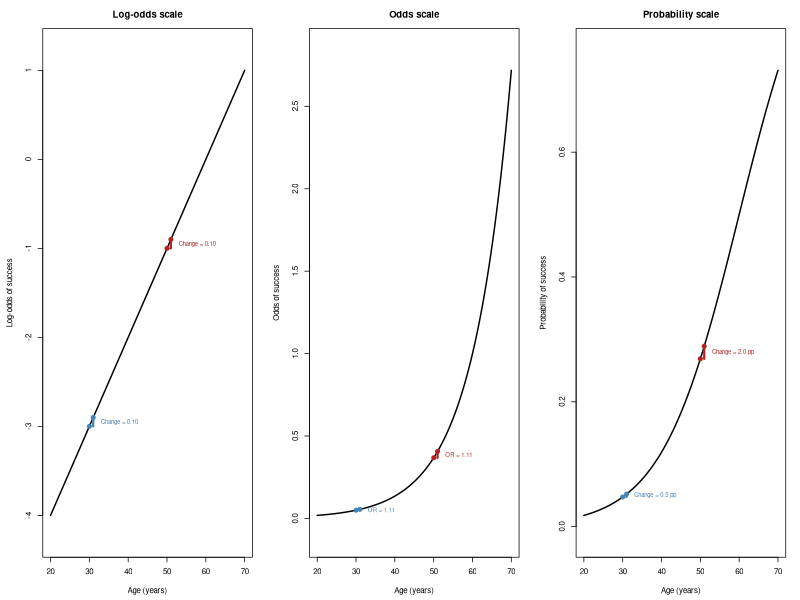

In [1]:

# Model parameters
beta0 <- -6
beta1 <- 0.10

# Ages to compare
ages <- c(30, 50)
delta <- 1

# Model functions
log_odds <- function(age) {
  beta0 + beta1 * age
}

odds <- function(age) {
  exp(log_odds(age))
}

prob <- function(age) {
  plogis(log_odds(age))
}

# Values for plotting
x <- seq(20, 70, length.out = 500)

# Colours
cols <- c("steelblue", "firebrick")

# Three panels
par(mfrow = c(1, 3), mar = c(4.5, 4.5, 3, 1.5))

for (scale in c("log-odds", "odds", "probability")) {

  if (scale == "log-odds") {
    f <- log_odds
    ylab <- "Log-odds of success"
    main <- "Log-odds scale"
  } else if (scale == "odds") {
    f <- odds
    ylab <- "Odds of success"
    main <- "Odds scale"
  } else {
    f <- prob
    ylab <- "Probability of success"
    main <- "Probability scale"
  }

  # Plot fitted relationship
  yrange <- range(f(x))
  ylim <- yrange + c(-1, 1) * diff(yrange) * 0.05

  plot(x, f(x),
       type = "l", lwd = 2,
       xlab = "Age (years)", ylab = ylab,
       main = main, ylim = ylim)

  for (i in seq_along(ages)) {

    age1 <- ages[i]
    age2 <- age1 + delta

    y1 <- f(age1)
    y2 <- f(age2)

    # Highlight the two predicted values
    points(c(age1, age2), c(y1, y2),
           pch = 19, col = cols[i], cex = 1.2)

    # Vertical difference
    segments(age2, y1, age2, y2,
             col = cols[i], lwd = 3)

    # Horizontal reference
    segments(age1, y1, age2, y1,
             col = cols[i], lty = 2)

    # Labels appropriate to each scale
    label <- switch(scale,
      "log-odds" = sprintf("Change = %.2f", y2 - y1),
      "odds" = sprintf("OR = %.2f", y2 / y1),
      "probability" = sprintf(
        "Change = %.1f pp", 100 * (y2 - y1))
    )

    text(age2 + 2, (y1 + y2) / 2,
         labels = label, col = cols[i],
         adj = 0, cex = 0.75)
  }
}

par(mfrow = c(1, 1))


So, you can say a 50% increase in the odds with each year of age, which will describe the whole slope. However, in real-world terms the effect of this increase will depend on the baseline. At the lower end, this is a smaller shift in the odds because 50% of a small number is still a small number. However, this gets bigger as $x$ increases. On the probability scale, this would be associated with a non-linear increase in the probability of success, leading to the S-shaped curve we saw before.

#### Odds Ratios and Probability
We cannot convert the slope itself into a probability because, on the probability scale, the relationship is not a straight line, it is an S-shaped curve. As such, the change in probability depends entirely on which values of $x$ are chosen. What we can do, is calculate probability of success from a given value of $x$.